# Devoir 1 – Les images sont des tableaux

**À rendre avant la séance 2 (12 novembre)**, dans ton dépôt Git `neuroimagery_exercise` (`git add`, `git commit`, `git push`).

En IRM, une image n'est rien d'autre qu'un grand tableau de nombres : une valeur d'intensité par voxel.
Ce devoir t'apprend à manipuler ces tableaux avec NumPy, d'abord sur une vraie image IRM, puis pour construire un premier modèle de champ récepteur (pRF), le cœur de notre projet.

**Comment travailler :**
- Les encadrés **Rappel** expliquent une notion et donnent un petit exemple déjà écrit : exécute-le (Maj + Entrée) et modifie-le pour voir ce qui change.
- Les **questions numérotées** sont pour toi : écris ton code dans la cellule vide qui suit.
- Quand une question demande une interprétation, réponds en une ou deux phrases dans une nouvelle cellule Markdown.
- Mets un titre et des unités sur chaque figure.
- Si tu bloques plus de 20 minutes sur une question, passe à la suivante et note ta question pour la séance.

Pour aller plus loin, les chapitres correspondants du manuel Nipraxis sont indiqués à chaque partie.

In [1]:
import numpy as np               # calcul sur tableaux
import matplotlib.pyplot as plt  # figures
import nibabel as nib            # lecture des images IRM (format NIfTI)
import nipraxis                  # téléchargement des données du manuel Nipraxis

plt.rcParams['image.cmap'] = 'gray'  # images en niveaux de gris par défaut

/home/hery/anaconda3/envs/neuro/lib/python3.12/site-packages/nipraxis/_fetcher.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


## Partie 0 – Rappels sur les tableaux NumPy

*Pour aller plus loin : [Introduction to NumPy](https://textbook.nipraxis.org/numpy_intro.html), [Arrays as images](https://textbook.nipraxis.org/arrays_and_images.html).*

> **Rappel – tableau, forme, indexation.**
> Un tableau NumPy (`np.array`) contient des nombres organisés en dimensions. Sa **forme** (`.shape`) donne la taille de chaque dimension : une image 2D de 15 lignes et 8 colonnes a la forme `(15, 8)`.
> On accède à un élément avec `tableau[ligne, colonne]` (on compte à partir de **0**), et à une portion avec `:` : `tableau[0:4, 3:]` donne les lignes 0 à 3 et les colonnes 3 jusqu'à la fin.

In [2]:
petit = np.array([[0, 1, 2, 3],
                  [4, 5, 6, 7],
                  [8, 9, 10, 11]])
print('Forme :', petit.shape)            # (3 lignes, 4 colonnes)
print('Élément ligne 1, colonne 2 :', petit[1, 2])
print('Première ligne :', petit[0])
print('Deux dernières colonnes :')
print(petit[:, 2:])

Forme : (3, 4)
Élément ligne 1, colonne 2 : 6
Première ligne : [0 1 2 3]
Deux dernières colonnes :
[[ 2  3]
 [ 6  7]
 [10 11]]


> **Rappel – un tableau s'affiche comme une image.**
> `plt.imshow(tableau)` affiche chaque nombre comme un pixel : plus la valeur est grande, plus le pixel est clair. `plt.colorbar()` ajoute l'échelle des valeurs.

Text(0.5, 1.0, 'Un tableau 3 x 4 affiché comme une image')

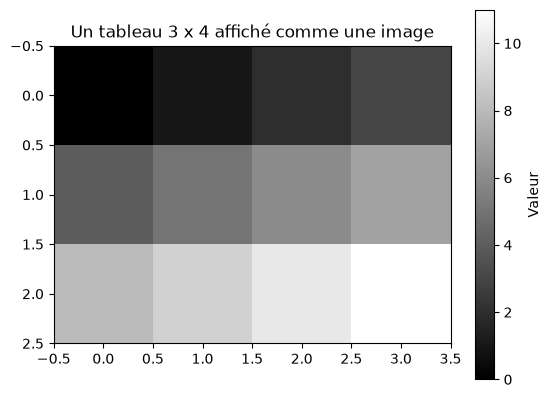

In [3]:
plt.imshow(petit)
plt.colorbar(label='Valeur')
plt.title('Un tableau 3 x 4 affiché comme une image')

> **Rappel – tableaux booléens (masques).**
> Une comparaison comme `petit > 5` s'applique à **chaque** élément et renvoie un tableau de `True` / `False` de même forme : c'est un **masque**.
> On peut ensuite utiliser ce masque pour sélectionner les valeurs : `petit[masque]` renvoie seulement les valeurs où le masque vaut `True`. Le symbole `~` inverse un masque.
> Astuce : `True` compte comme 1 et `False` comme 0, donc `masque.mean()` donne la **proportion** d'éléments `True`.

In [4]:
masque_exemple = petit > 5
print(masque_exemple)
print('Valeurs > 5 :', petit[masque_exemple])
print('Valeurs <= 5 :', petit[~masque_exemple])
print('Proportion > 5 :', masque_exemple.mean())

[[False False False False]
 [False False  True  True]
 [ True  True  True  True]]
Valeurs > 5 : [ 6  7  8  9 10 11]
Valeurs <= 5 : [0 1 2 3 4 5]
Proportion > 5 : 0.5


> **Rappel – changer la forme d'un tableau.**
> `np.ravel(tableau)` aplatit un tableau en une seule ligne (1D). `tableau.reshape(nouvelle_forme)` change la forme sans changer les valeurs, à condition que le nombre total d'éléments reste le même. `tableau.T` échange lignes et colonnes (transposition).

In [5]:
print(np.ravel(petit))          # 12 valeurs en 1D
print(petit.reshape(4, 3))      # même 12 valeurs, forme (4, 3)
print(petit.T.shape)            # (4, 3) : lignes et colonnes échangées

[ 0  1  2  3  4  5  6  7  8  9 10 11]
[[ 0  1  2]
 [ 3  4  5]
 [ 6  7  8]
 [ 9 10 11]]
(4, 3)


## Partie 1 – Une coupe de cerveau comme tableau

*Pour aller plus loin : [What is an image?](https://textbook.nipraxis.org/what_is_an_image.html), [Three-dimensional images, NIfTI](https://textbook.nipraxis.org/images_3d.html).*

> **Rappel – les images IRM et le format NIfTI.**
> Une IRM anatomique est un tableau **3D** : une valeur d'intensité pour chaque voxel (petit cube de cerveau) le long de trois axes.
> Elle est stockée dans un fichier NIfTI (`.nii`), qui contient un **en-tête** (dimensions, taille des voxels, orientation…) puis les valeurs.
> La bibliothèque `nibabel` lit ces fichiers : `nib.load(fichier)` ouvre l'image, et `.get_fdata()` renvoie le tableau NumPy des intensités.
> `nipraxis.fetch_file(nom)` télécharge un fichier d'exemple du manuel (une seule fois) et renvoie son chemin sur ton disque.

On utilise l'image anatomique d'un participant du jeu de données du manuel Nipraxis.

In [6]:
fname = nipraxis.fetch_file('ds114_sub009_highres.nii')
print('Fichier :', fname)
img = nib.load(fname)
data = img.get_fdata()

Fichier : /home/hery/.cache/nipraxis/0.5/ds114_sub009_highres.nii


**1.** Quelle est la forme (`shape`) de `data` ? Combien de voxels contient l'image au total (`.size`) ? Quelles sont les valeurs minimale et maximale (`.min()`, `.max()`) ?

In [7]:
# Ton code ici
print('La forme de data :', data.shape)
print('Le nombre de voxels :', data.size)
print('La valeur minimale : ', data.min())
print('La valeur maximale : ', data.max())


La forme de data : (256, 156, 256)
Le nombre de voxels : 10223616
La valeur minimale :  0.0
La valeur maximale :  3237.0


> **Rappel – extraire une coupe 2D d'un volume 3D.**
> `data[:, :, 128]` garde tous les éléments des deux premiers axes et seulement la position 128 du troisième : on obtient une image 2D.
> Selon l'orientation de l'image, la coupe peut apparaître couchée. `coupe.T` la fait pivoter, et `plt.imshow(..., origin='lower')` place la ligne 0 en bas (comme sur un graphique) plutôt qu'en haut.

**2.** Extrais la coupe 2D `data[:, :, 128]` et affiche-la, avec `.T` et `origin='lower'`. De quel type de coupe s'agit-il : axiale (vue de dessus), coronale (vue de face) ou sagittale (vue de profil) ?

[[0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]]


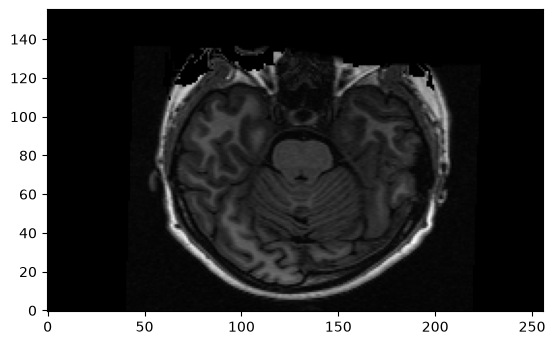

In [8]:
# Ton code ici
coupe = data[:, :, 128]
print(coupe)
plt.imshow(coupe.T, origin='lower')

Il s'agit d'une coupe coronale (vue de face)

> **Rappel – histogramme.**
> Un histogramme compte combien de valeurs tombent dans chaque intervalle d'intensité. Pour l'utiliser, il faut d'abord un tableau 1D : `np.ravel(coupe)`. Puis `plt.hist(valeurs, bins=100)` découpe la plage des intensités en 100 intervalles.
> Dans une image IRM, le fond (l'air autour de la tête) est sombre et occupe beaucoup de voxels : il forme un grand pic près de 0.

**3.** Trace l'histogramme des intensités de ta coupe. Quel seuil d'intensité te semble séparer le fond de la tête ?

(array([1.6917e+04, 5.6100e+02, 3.6190e+03, 3.0330e+03, 1.0620e+03,
        5.2700e+02, 5.2000e+02, 4.6300e+02, 4.9000e+02, 5.9000e+02,
        6.3700e+02, 7.0500e+02, 7.7800e+02, 7.5300e+02, 7.7800e+02,
        7.9700e+02, 7.2600e+02, 6.9700e+02, 6.3300e+02, 5.2800e+02,
        5.3200e+02, 5.1600e+02, 4.1200e+02, 3.2400e+02, 2.8100e+02,
        2.6500e+02, 2.0400e+02, 1.9500e+02, 1.7000e+02, 1.6200e+02,
        1.4400e+02, 1.0900e+02, 1.1200e+02, 8.2000e+01, 6.0000e+01,
        8.3000e+01, 5.4000e+01, 4.5000e+01, 3.6000e+01, 5.0000e+01,
        5.1000e+01, 4.9000e+01, 3.9000e+01, 4.2000e+01, 4.2000e+01,
        3.3000e+01, 3.9000e+01, 3.9000e+01, 3.1000e+01, 3.6000e+01,
        4.1000e+01, 2.5000e+01, 2.5000e+01, 3.6000e+01, 4.0000e+01,
        4.8000e+01, 4.2000e+01, 3.7000e+01, 4.5000e+01, 3.5000e+01,
        4.4000e+01, 2.9000e+01, 3.5000e+01, 2.8000e+01, 3.5000e+01,
        1.6000e+01, 2.4000e+01, 1.8000e+01, 2.2000e+01, 2.2000e+01,
        2.0000e+01, 1.6000e+01, 1.5000e+01, 1.80

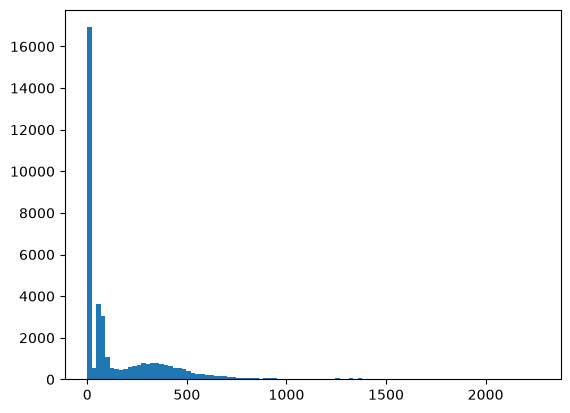

In [9]:
# Ton code ici
valeurs = np.ravel(coupe)
plt.hist(valeurs, bins=100)

Le seuil d'intensité qui sépare le fond de la tête est 10.

**4.** Crée un masque `masque = coupe > seuil` avec ton seuil et affiche-le (comme à la question 2). Quelle proportion des voxels de la coupe est au-dessus du seuil ?

In [10]:
# Ton code ici
masque = coupe > 10
print(coupe[masque])
print('La proportion des voxels :', masque.mean())

[ 64.          65.          81.         ...  69.         109.
  31.70326233]
La proportion des voxels : 0.5772485977564102


**5.** Utilise le masque pour calculer l'intensité moyenne **dans** la tête (`coupe[masque]`) et **hors** de la tête (`coupe[~masque]`).

In [11]:
# Ton code ici
print('intensité moyenne dans la tête :', coupe[masque].mean())
print('intensité moyenne hors de la tête :', coupe[~masque].mean())

intensité moyenne dans la tête : 317.6743399652696
intensité moyenne hors de la tête : 0.0030342333267235413


**6.** *Réflexion :* ton masque sépare-t-il le **cerveau** du reste de la tête (crâne, peau, graisse) ? Pourquoi un simple seuil d'intensité ne suffit-il pas ?

Non, le masque ne sépare pas le cerveau du reste de la tête, il sépare seulement la tête entière du fond (air). Un simple seuil d'intensité ne suffit pas car le crâne, la peau et la graisse ont aussi des intensités supérieures au seuil, parfois proches de celles du cerveau.

## Avant de rendre

1. *Kernel → Restart & Run All* : vérifie que tout le notebook s'exécute sans erreur, du début à la fin.
2. Dans le terminal, depuis ton dépôt `neuroimagery_exercise` :
```
git add devoir1.ipynb
git commit -m "Devoir 1 : images comme tableaux"
git push
```